In [9]:
!pip install optuna tensorflow numpy pandas matplotlib scikit-learn

In [47]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import optuna
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_percentage_error

# ==========================================
# 1. SETUP SEED (AGAR KONSISTEN)
# ==========================================
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [49]:
df = pd.read_excel("/content/Harga Beras Jabar 2013-2024.xlsx", parse_dates=["Date"], index_col="Date")
df = df.sort_index()
print("Data Loaded. Shape:", df.shape)

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df)

def create_sequences(data, n_steps):
    X, y = [], []
    for i in range(len(data) - n_steps):
        X.append(data[i:i + n_steps])
        y.append(data[i + n_steps])
    return np.array(X), np.array(y)

Data Loaded. Shape: (144, 1)


In [ ]:
# ==========================================
# 3. OPTUNA TUNING
# ==========================================
def objective(trial):
    # Clear session agar memory tidak bocor dan seed ter-reset tiap trial
    tf.keras.backend.clear_session()

    n_steps = trial.suggest_int('n_steps', 3, 24)
    units = trial.suggest_int('units', 32, 128)
    learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True)
    batch_size = trial.suggest_categorical('batch_size', [16, 32])

    X, y = create_sequences(scaled_data, n_steps)

    test_size = 12
    X_train, X_test = X[:-test_size], X[-test_size:]
    y_train, y_test = y[:-test_size], y[-test_size:]

    model = Sequential([
        LSTM(units, input_shape=(n_steps, 1)),
        Dense(1)
    ])

    model.compile(optimizer=Adam(learning_rate=learning_rate), loss='mse')

    # shuffle=False bisa membantu konsistensi pada time series,
    # tapi shuffle=True (default) lebih bagus untuk belajar.
    # Karena global seed sudah diset, shuffle=True tetap aman (konsisten).
    model.fit(X_train, y_train, epochs=20, batch_size=batch_size, verbose=0, shuffle=False)

    y_pred = scaler.inverse_transform(model.predict(X_test, verbose=0))
    y_true = scaler.inverse_transform(y_test)

    return mean_absolute_percentage_error(y_true, y_pred)

# Kunci Seed Optuna disini
sampler = optuna.samplers.TPESampler(seed=SEED)
study = optuna.create_study(direction='minimize', sampler=sampler)
study.optimize(objective, n_trials=100)

print(f"MAPE Terbaik: {study.best_value * 100:.2f}%")
print("Parameter Terbaik:", study.best_params)

[I 2025-11-20 14:23:54,645] A new study created in memory with name: no-name-4a5073f6-4796-4cf4-8cb7-377c33d3149f
[I 2025-11-20 14:23:58,467] Trial 0 finished with value: 0.10630770845436417 and parameters: {'n_steps': 11, 'units': 124, 'learning_rate': 0.0029106359131330704, 'batch_size': 16}. Best is trial 0 with value: 0.10630770845436417.
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
[I 2025-11-20 14:24:02,669] Trial 1 finished with value: 0.08422903207836868 and parameters: {'n_steps': 6, 'units': 37, 'learning_rate': 0.005399484409787433, 'batch_size': 32}. Best is trial 1 with value: 0.08422903207836868.
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a 

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step


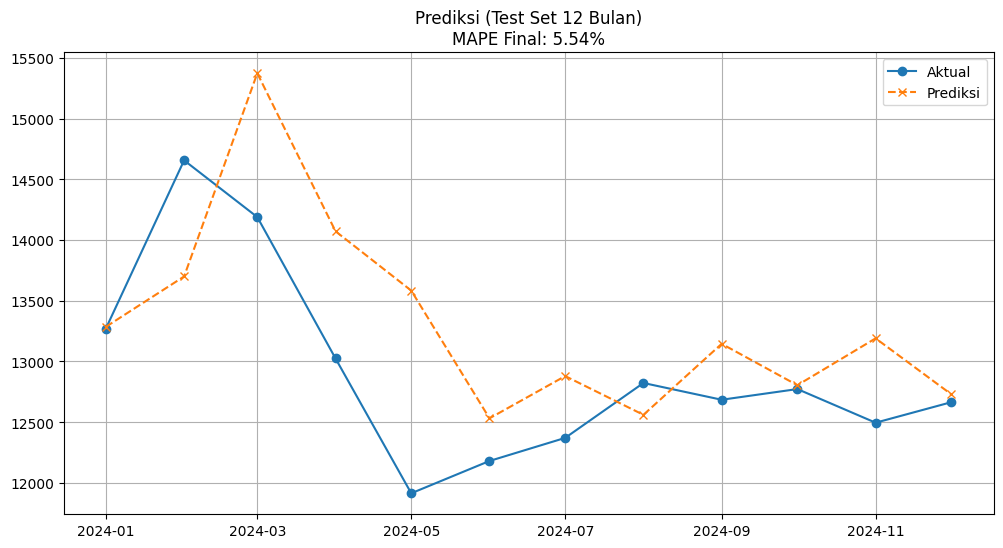

In [54]:
# ==========================================
# 4. FINAL MODEL
# ==========================================
tf.keras.backend.clear_session() # Reset lagi sebelum training final

params = study.best_params
n_steps = params['n_steps']

X, y = create_sequences(scaled_data, n_steps)
test_size = 12
X_train, X_test = X[:-test_size], X[-test_size:]
y_train, y_test = y[:-test_size], y[-test_size:]

model = Sequential([
    LSTM(params['units'], input_shape=(n_steps, 1)),
    Dense(1)
])
model.compile(optimizer=Adam(learning_rate=params['learning_rate']), loss='mse')
model.fit(X_train, y_train, epochs=100, batch_size=params['batch_size'], verbose=0, shuffle=False)

y_pred = scaler.inverse_transform(model.predict(X_test))
y_true = scaler.inverse_transform(y_test)

# Plot
plt.figure(figsize=(12, 6))
plt.plot(df.index[-12:], y_true, label='Aktual', marker='o')
plt.plot(df.index[-12:], y_pred, label='Prediksi', marker='x', linestyle='--')
plt.title(f"Prediksi (Test Set 12 Bulan)\nMAPE Final: {study.best_value*100:.2f}%")
plt.legend()
plt.grid(True)
plt.show()